# Classificação de lesões de pele com CNN professor-aluno

**Projeto Final – InsperAI · Felipe Gava e Lucas Briones**

## Problema
O câncer de pele é o tipo de câncer mais comum, e o melanoma, embora menos frequente, é o mais letal. Quando é detectado cedo, a cura é muito mais provável. O exame de rotina do dermatologista é a **dermatoscopia**: uma lente com iluminação que mostra estruturas da pele invisíveis a olho nu. Interpretar essas imagens exige experiência, e mesmo especialistas erram uma parte relevante dos casos. O diagnóstico definitivo só vem da biópsia (histopatologia).

## Objetivo
Treinar um modelo que, a partir de uma **foto dermatoscópica**, indique o **tipo da lesão** entre 8 classes:

| Classe | Lesão | Maligna? |
|---|---|---|
| `mel` | melanoma | sim |
| `bcc` | carcinoma basocelular | sim |
| `scc` | carcinoma espinocelular | sim |
| `ak` | ceratose actínica (pré-cancerígena) | sim* |
| `nv` | nevo melanocítico ("pinta" comum) | não |
| `bkl` | lesão benigna tipo ceratose | não |
| `df` | dermatofibroma | não |
| `vasc` | lesão vascular | não |

\* lesão pré-maligna, agrupada com as malignas na triagem.

O uso pensado é o de **apoio à decisão e triagem** num consultório: o dermatologista fotografa a lesão, o modelo sugere o diagnóstico e destaca os casos suspeitos de câncer para biópsia. A decisão continua sendo do médico.

## Abordagem
1. **Professor**: uma CNN grande, pré-treinada no ImageNet e ajustada nas imagens de pele, buscando a máxima acurácia (este notebook e `kaggle_professor.ipynb`, na GPU).
2. **Aluno** (próxima etapa): uma CNN menor e mais rápida, treinada por **destilação de conhecimento** para imitar as probabilidades do professor, inclusive nas imagens sem rótulo. A ideia é chegar perto da acurácia do professor com um modelo leve o bastante para rodar num computador de consultório ou no celular.

## Métrica
A base é muito desbalanceada: cerca de metade das imagens são nevos benignos. Um modelo que respondesse sempre "nevo" teria ~50% de acurácia sem servir para nada. Por isso a métrica principal é a **acurácia balanceada**, a média da sensibilidade de cada classe e métrica oficial do desafio ISIC. A acurácia comum também é reportada.

## Estrutura
1. **Carregamento e exploração dos dados**: a base, as classes, as origens das imagens e os metadados.
2. **Modelo**: a arquitetura do professor e as estratégias para aumentar a acurácia.
3. **Treino**: pré-processamento das imagens e treino em duas fases.
4. **Teste**: avaliação no teste do ISIC 2018, triagem maligno/benigno e comparação com dermatologistas.
5. **Fotos de celular**: ajuste do professor para foto de celular, com augmentation que simula celular, e o teste em fotos reais.
6. **Registro de iterações**: o que foi testado em cada rodada e os resultados.

In [1]:
%pip install -q tensorflow numpy pandas matplotlib seaborn scikit-learn pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import keras
from keras import layers, ops, applications, callbacks, losses, metrics, optimizers

from PIL import Image
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)

from prepare_data import CLASSES, DEFAULT_DIR, DX_NAMES, HAM_CLASSES, load_labels
from pipeline import CLASS_IDX, HAM_IDX, N_META, build_cache, class_weights, make_datasets, make_ds

SEED = 42
keras.utils.set_random_seed(SEED)

print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026101904


GPUs: []


# Carregamento e exploração dos dados

Usamos imagens públicas dos desafios do **ISIC** (International Skin Imaging Collaboration), unificadas pelo `prepare_data.py`:

- **Treino e validação: ISIC 2019**, 25.331 imagens de três fontes: **HAM10000** (Viena e Austrália), **BCN_20000** (Barcelona) e **MSK** (Nova York). Os rótulos vêm de biópsia na maior parte dos casos malignos; nos benignos, também de acompanhamento ou consenso de especialistas.
- **Teste: ISIC 2018 Task 3**, 1.511 imagens que o modelo nunca vê no treino. Esse teste é rotulado nas 7 classes do HAM10000, em que `akiec` junta `ak` e `scc`. Por isso as previsões das 8 classes são somadas nessas 7 na hora de avaliar.
- **Sem rótulo**: 6.726 imagens do teste do ISIC 2019, reservadas para a destilação do aluno.

A validação (15%) é sorteada **por lesão** (`lesion_id`), e não por imagem. Algumas lesões têm várias fotos, e se uma foto ficasse no treino e outra na validação, o modelo seria avaliado em algo que já viu.

In [3]:
# Base única gerada pelo prepare_data.py (ver README):
# train/val = ISIC 2019 (HAM10000 + BCN_20000 + MSK), 8 classes
# test      = ISIC 2018 Task 3, rotulado só nas 7 classes do HAM (coluna dx_ham)
# unlabeled = resto do teste do ISIC 2019, sem rótulo
df = load_labels()
train_df, val_df, test_df, unlabeled_df = (
    df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test", "unlabeled"]
)
print({s: len(d) for s, d in zip(["train", "val", "test", "unlabeled"],
                                 [train_df, val_df, test_df, unlabeled_df])})
df.head()

{'train': 21486, 'val': 3845, 'test': 1511, 'unlabeled': 6726}


,image_id,file_id,lesion_id,split,dx,dx_ham,dx_name,malignant,source,dataset,dx_type,age_approx,sex,site,image_path,mask_path
0,ISIC_0000000,ISIC_0000000,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,55.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
1,ISIC_0000001,ISIC_0000001,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,female,anterior torso,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
2,ISIC_0000002,ISIC_0000002,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,60.0,female,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN
3,ISIC_0000003,ISIC_0000003,NaN,train,nv,nv,Nevo melanocítico,0.0,MSK,NaN,NaN,30.0,male,upper extremity,C:\Users\felip\datasets\lesoes_pele\train\nv\I...,NaN
4,ISIC_0000004,ISIC_0000004,NaN,train,mel,mel,Melanoma,1.0,MSK,NaN,NaN,80.0,male,posterior torso,C:\Users\felip\datasets\lesoes_pele\train\mel\...,NaN


In [4]:
# Classes por split (no teste, o rótulo disponível é o dx_ham: akiec = ak + scc)
labeled = df[df["split"] != "unlabeled"]
pd.crosstab(labeled["dx"].fillna(labeled["dx_ham"]), labeled["split"], margins=True)

split,test,train,val,All
dx,,,,
ak,0,719,148,867
akiec,43,0,0,43
bcc,93,2824,499,3416
bkl,217,2251,373,2841
df,44,200,39,283
mel,171,3855,667,4693
nv,908,10893,1982,13783
scc,0,533,95,628
vasc,35,211,42,288


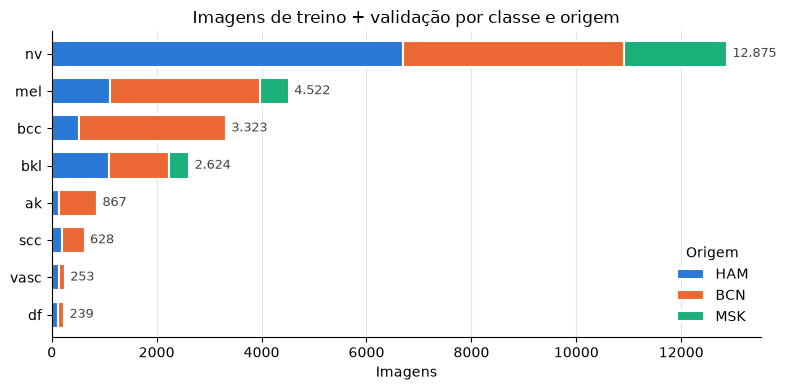

dx,ak,bcc,bkl,df,mel,nv,scc,vasc
source,,,,,,,,
HAM,1.3,5.1,11.0,1.1,11.1,66.9,2.0,1.4
BCN,5.9,22.6,9.2,1.0,23.0,33.9,3.5,0.9
MSK,0.0,0.0,13.3,0.0,19.0,67.7,0.0,0.0


In [5]:
# Treino + validação por classe e origem
SOURCES = ["HAM", "BCN", "MSK"]
SOURCE_COLORS = ["#2a78d6", "#eb6834", "#1baf7a"]

trainval = df[df["split"].isin(["train", "val"])]
counts = pd.crosstab(trainval["dx"], trainval["source"])[SOURCES]
counts = counts.loc[counts.sum(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(8, 4))
counts.plot.barh(stacked=True, color=SOURCE_COLORS, edgecolor="white", linewidth=1.5, width=0.7, ax=ax)
for i, total in enumerate(counts.sum(axis=1)):
    ax.text(total + 100, i, f"{total:,}".replace(",", "."), va="center", fontsize=9, color="#444")
ax.set(xlabel="Imagens", ylabel="", title="Imagens de treino + validação por classe e origem")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
ax.legend(title="Origem", frameon=False, loc="lower right")
plt.tight_layout()
plt.show()

# Proporção (%) de cada classe dentro de cada origem
display((pd.crosstab(trainval["source"], trainval["dx"], normalize="index") * 100).round(1).loc[SOURCES, CLASSES])

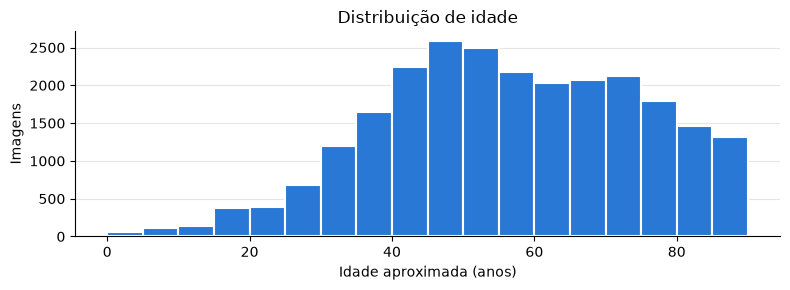

Faltantes (%):
age_approx     1.7
sex            1.5
site          10.2


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
site,,,,,,,,
(vazio),22,72,273,3,127,2049,6,31
anterior torso,92,1114,445,43,1331,3699,113,78
head/neck,598,1131,1001,0,880,767,174,36
lateral torso,0,0,6,0,14,34,0,0
lower extremity,66,462,412,138,796,2876,182,58
oral/genital,0,0,16,1,19,69,0,2
palms/soles,6,0,7,0,201,168,13,3
posterior torso,4,186,230,2,430,1888,25,22
upper extremity,79,358,234,52,724,1325,115,23


dx,ak,bcc,bkl,df,mel,nv,scc,vasc
sex,,,,,,,,
(vazio),3,6,23,0,81,271,0,0
female,406,1317,1134,117,1980,6379,203,125
male,458,2000,1467,122,2461,6225,425,128


In [6]:
# Metadados clínicos (treino + validação)
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(trainval["age_approx"].dropna(), bins=np.arange(0, 95, 5), color="#2a78d6", edgecolor="white", linewidth=1.5)
ax.set(xlabel="Idade aproximada (anos)", ylabel="Imagens", title="Distribuição de idade")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

print("Faltantes (%):")
print((trainval[["age_approx", "sex", "site"]].isna().mean() * 100).round(1).to_string())
display(pd.crosstab(trainval["site"].fillna("(vazio)"), trainval["dx"])[CLASSES])
display(pd.crosstab(trainval["sex"].fillna("(vazio)"), trainval["dx"])[CLASSES])

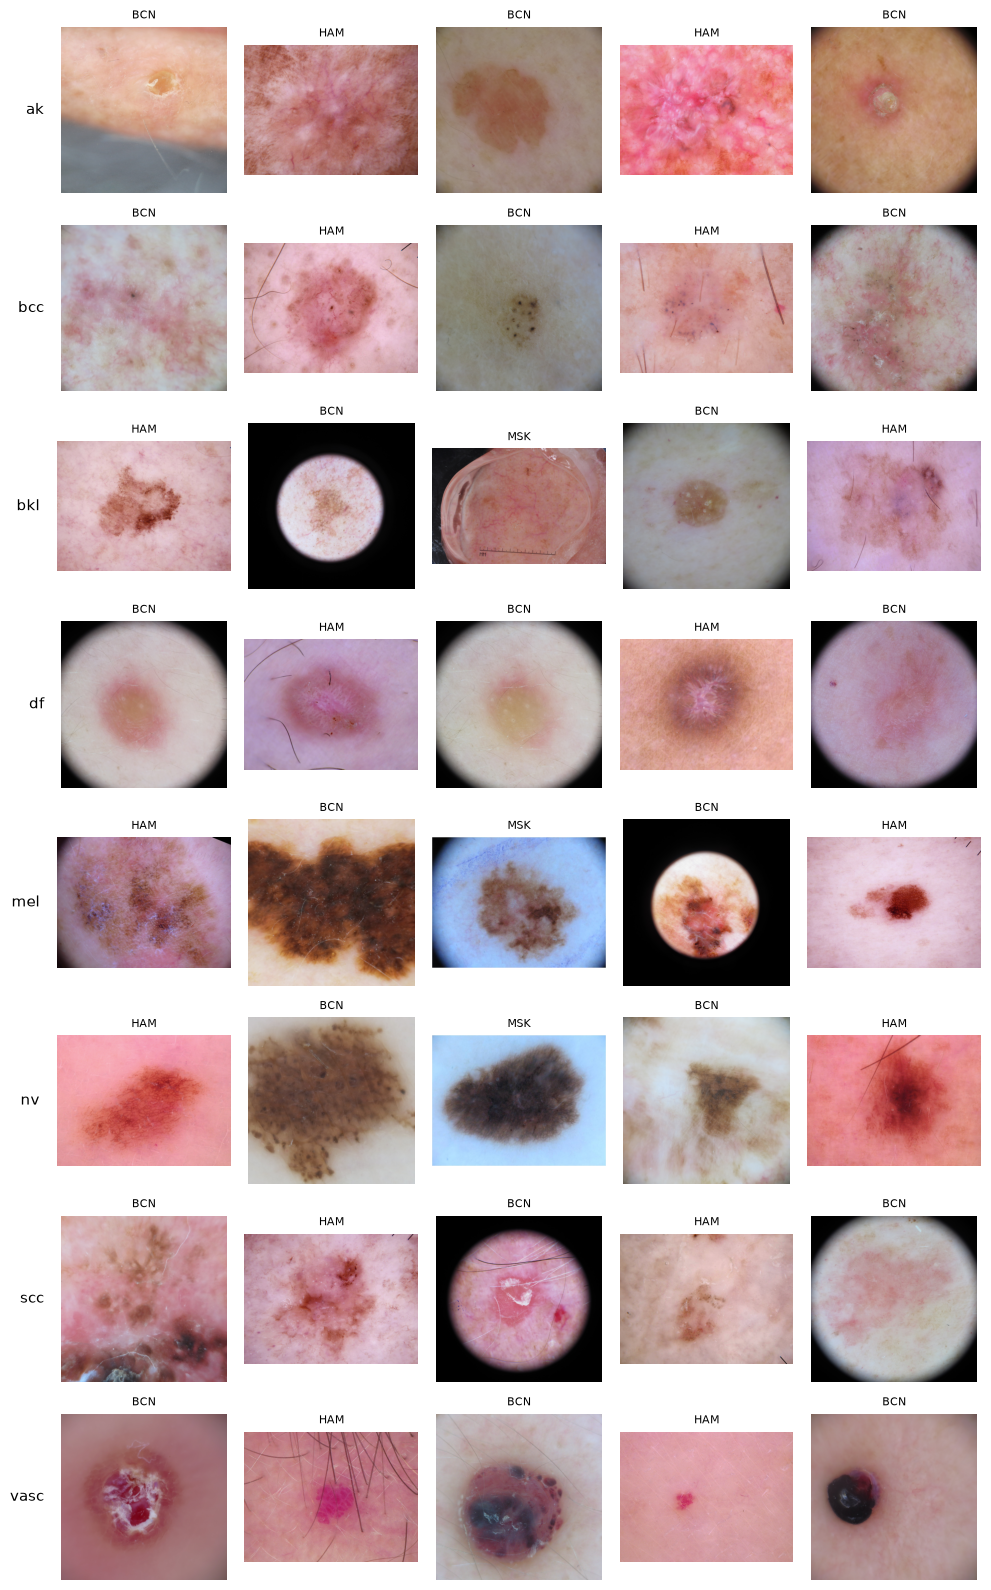

source
BCN                                   {(1024, 1024): 50}
HAM                                     {(600, 450): 50}
MSK    {(1024, 680): 19, (1024, 768): 10, (1024, 685)...
Name: size, dtype: object

In [7]:
# Exemplos de cada classe, misturando as origens
N_EXAMPLES = 5
fig, axes = plt.subplots(len(CLASSES), N_EXAMPLES, figsize=(2 * N_EXAMPLES, 2 * len(CLASSES)))
for row, dx in zip(axes, CLASSES):
    pool = train_df[train_df["dx"] == dx].groupby("source").head(N_EXAMPLES)
    sample = pool.sample(min(N_EXAMPLES, len(pool)), random_state=SEED)
    for ax in row:
        ax.axis("off")
    for ax, r in zip(row, sample.itertuples()):
        ax.imshow(Image.open(r.image_path))
        ax.set_title(r.source, fontsize=8)
    row[0].text(-0.1, 0.5, dx, transform=row[0].transAxes, ha="right", va="center", fontsize=11)
plt.tight_layout()
plt.show()

# Tamanho das imagens por origem (amostra)
sizes = train_df.groupby("source").sample(50, random_state=SEED)
sizes["size"] = [Image.open(p).size for p in sizes["image_path"]]
sizes.groupby("source")["size"].agg(lambda s: s.value_counts().head(3).to_dict())

In [8]:
# Datasets do TensorFlow (pipeline.py, o mesmo código usado no Kaggle).
# train/val: rótulos em CLASSES; test: rótulos em HAM_CLASSES; unlabeled: sem rótulo
IMG_SIZE = 224
BATCH_SIZE = 32

ds = make_datasets(df, img_size=IMG_SIZE, batch_size=BATCH_SIZE)
train_ds, val_ds, test_ds, unlabeled_ds = ds["train"], ds["val"], ds["test"], ds["unlabeled"]

# pesos para compensar o desbalanceamento (nv domina o treino)
class_weight = class_weights(train_df["dx"])

images, labels = next(iter(train_ds))
print("batch:", images.shape, labels.shape)
print("pesos:", {CLASSES[i]: round(w, 2) for i, w in class_weight.items()})

batch: (32, 224, 224, 3) (32,)
pesos: {'ak': 3.74, 'bcc': 0.95, 'bkl': 1.19, 'df': 13.43, 'mel': 0.7, 'nv': 0.25, 'scc': 5.04, 'vasc': 12.73}


# Modelo

Professor treinado no PC, que não tem GPU: **EfficientNetV2-B0 em 224 px**. A versão completa para GPU (EfficientNetV2-S/ConvNeXt em 384 px, com ensemble) está em `kaggle_professor.ipynb`; as estratégias são as mesmas:

- **Transfer learning em duas fases**: primeiro só a cabeça, com a rede pré-treinada no ImageNet congelada (é o *baseline* de embeddings), depois o ajuste fino da rede inteira, com as BatchNormalization congeladas (estatísticas do ImageNet), o que estabiliza o ajuste fino e, na CPU, o deixa 2× mais rápido e com ~30% menos memória.
- **Constância de cor Shades of Gray**: uniformiza a cor entre os dermatoscópios do HAM, do BCN e do MSK.
- **Data augmentation**: recortes, rotações, espelhamentos, variação de cor e uma **borda circular artificial**, para o modelo não usar a borda preta do BCN como atalho.
- **Metadados** (idade, sexo, região do corpo) como segunda entrada.
- **Desbalanceamento**: entropia cruzada comum + ajuste de logits pelo prior do treino (Menon et al., 2021), com a intensidade escolhida na validação.
- **Otimização**: AdamW, aquecimento + decaimento cosseno do learning rate, melhor época pela acurácia balanceada da validação, parada antecipada.
- **Test-time augmentation**: média das previsões em 8 versões da imagem.

In [9]:
BACKBONE = applications.EfficientNetV2B0
IMG_SIZE = 224
BATCH_SIZE = 32
USE_META = True     # idade, sexo e região do corpo como segunda entrada
HEAD_EPOCHS = 2     # fase 1: rede congelada, só a cabeça
EPOCHS = 20         # fase 2: ajuste fino da rede inteira (máximo; para antes se estagnar)
PATIENCE = 5        # épocas sem melhorar a acurácia balanceada da validação antes de parar
LR = 3e-4           # learning rate de pico da fase 2
WEIGHT_DECAY = 0.02
TTA_VIEWS = 8       # 4 rotações x 2 espelhamentos na previsão de validação e teste
CACHE_SIZE = 288    # lado menor das imagens pré-processadas (folga para o recorte aleatório)

# modelo treinado e previsões ficam no repositório (modelos/), para quem clonar rodar o notebook
# sem treinar de novo; o cache das imagens fica fora, junto com a base
OUT = Path(os.environ.get("TEACHER_DIR", Path("modelos") / "professor_effv2b0"))
CACHE_DIR = Path(os.environ.get("CACHE_DIR", DEFAULT_DIR.parent / f"lesoes_pele_cache_{CACHE_SIZE}"))

SMOKE_TEST = os.environ.get("SMOKE_TEST") == "1"  # teste rápido do código, com poucas imagens
if SMOKE_TEST:
    IMG_SIZE, BATCH_SIZE, HEAD_EPOCHS, EPOCHS, TTA_VIEWS = 64, 8, 1, 1, 2
OUT.mkdir(parents=True, exist_ok=True)


def build_model():
    """Backbone pré-treinado + cabeça que junta a imagem e os metadados.

    Devolve o modelo e o backbone (para congelar/descongelar). A saída são logits.
    """
    # pooling="avg" entrega um vetor de características (embedding) por imagem; a rede já traz
    # a normalização da entrada de 0-255
    base = BACKBONE(include_top=False, weights="imagenet", input_shape=(IMG_SIZE, IMG_SIZE, 3), pooling="avg")
    image = keras.Input((IMG_SIZE, IMG_SIZE, 3), name="image")
    x = layers.Dropout(0.3)(base(image))
    inputs = image
    if USE_META:
        meta = keras.Input((N_META,), name="meta")
        m = layers.Dense(64, activation="relu")(layers.Dropout(0.1)(meta))
        m = layers.BatchNormalization()(m)
        x = layers.Concatenate()([x, m])
        inputs = {"image": image, "meta": meta}
    logits = layers.Dense(len(CLASSES), name="logits")(x)
    return keras.Model(inputs, logits, name="professor"), base


model, base = build_model()
print(f"{model.count_params() / 1e6:.1f} M parâmetros ({base.count_params() / 1e6:.1f} M no backbone)")
del model, base

5.9 M parâmetros (5.9 M no backbone)


# Treino

O treino tem duas fases (*transfer learning*):

1. **Fase 1, só a cabeça**: o backbone pré-treinado fica congelado e só a camada final aprende. É o *baseline* "embeddings do ImageNet + classificador", que mostra quanto a rede já sabe sem se adaptar à pele.
2. **Fase 2, ajuste fino**: a rede inteira é ajustada com learning rate baixo. É daqui que vem o grosso do ganho.

O PC não tem GPU, então tudo roda na CPU, a cerca de 17 min por época. Por isso o treino é **retomável**: cada época deixa um backup em `~/datasets/modelos/professor_effv2b0/`, e rodar o notebook de novo depois de uma interrupção continua da última época concluída. Ao final, as probabilidades de todas as imagens ficam salvas em `probs.npz`, e as execuções seguintes do notebook só as carregam.

In [10]:
# Pré-processamento (Shades of Gray + lado menor de 288 px), feito uma única vez
data = df
if SMOKE_TEST:
    data = pd.concat([
        df[df["split"].isin(["train", "val"])].groupby(["split", "dx"]).head(4),
        df[df["split"] == "test"].groupby("dx_ham").head(3),
        df[df["split"] == "unlabeled"].head(8),
    ])
data = build_cache(data, CACHE_DIR, size=CACHE_SIZE)

split = {s: data[data["split"] == s].reset_index(drop=True) for s in ["train", "val", "test", "unlabeled"]}
y_val = split["val"]["dx"].map(CLASS_IDX).values
y_test = split["test"]["dx_ham"].map(HAM_IDX).values

# Prior do treino. O modelo aprende com entropia cruzada comum (probabilidades calibradas, boas
# para a destilação) e, na hora de decidir, subtrai tau * log(prior) dos logits para não
# favorecer as classes grandes como nv (ajuste de logits, Menon et al., 2021).
prior = split["train"]["dx"].value_counts(normalize=True).reindex(CLASSES).values
LOG_PRIOR = np.log(prior)
print({s: len(d) for s, d in split.items()})
print("prior do treino:", {c: round(float(p), 3) for c, p in zip(CLASSES, prior)})

{'train': 21486, 'val': 3845, 'test': 1511, 'unlabeled': 6726}
prior do treino: {'ak': 0.033, 'bcc': 0.131, 'bkl': 0.105, 'df': 0.009, 'mel': 0.179, 'nv': 0.507, 'scc': 0.025, 'vasc': 0.01}


In [11]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(axis=1, keepdims=True)


class ValMetrics(callbacks.Callback):
    """A cada época: perda, acurácia e acurácia balanceada na validação.

    A acurácia balanceada (média da sensibilidade das classes, métrica oficial do ISIC) usa os
    logits ajustados pelo prior; é ela que escolhe o melhor checkpoint.
    """

    def __init__(self, ds, y):
        super().__init__()
        self.ds, self.y = ds, y

    def on_epoch_end(self, epoch, logs=None):
        logits = self.model.predict(self.ds, verbose=0)
        p = softmax(logits)
        logs["val_loss"] = float(-np.log(p[np.arange(len(self.y)), self.y] + 1e-12).mean())
        logs["val_acc"] = accuracy_score(self.y, logits.argmax(1))
        logs["val_bal_acc"] = balanced_accuracy_score(self.y, (logits - LOG_PRIOR).argmax(1))
        print(f"  época {epoch + 1}: val_loss={logs['val_loss']:.4f} "
              f"val_acc={logs['val_acc']:.4f} val_bal_acc={logs['val_bal_acc']:.4f}")


def tta_view(x, k):
    """Uma das 8 versões da imagem (4 rotações x espelhamento) do test-time augmentation."""
    img = x["image"] if USE_META else x
    img = tf.image.rot90(img, k % 4)
    if k >= 4:
        img = tf.image.flip_left_right(img)
    return {**x, "image": img} if USE_META else img


def predict_tta(model, data, views):
    """Probabilidades médias nas `views` versões de cada imagem (views=1: só a original)."""
    ds = make_ds(data, IMG_SIZE, BATCH_SIZE, labels=None, use_meta=USE_META)
    probs = 0
    for k in range(views):
        probs = probs + softmax(model.predict(ds.map(lambda x, k=k: tta_view(x, k)), verbose=0))
    return probs / views


def train_teacher():
    """Treina em duas fases e devolve o melhor modelo.

    Retomável: cada época deixa um backup em OUT, e rodar de novo depois de uma interrupção
    continua da última época concluída.
    """
    train_ds = make_ds(split["train"], IMG_SIZE, BATCH_SIZE, training=True, use_meta=USE_META)
    val_ds = make_ds(split["val"], IMG_SIZE, BATCH_SIZE, labels=None, use_meta=USE_META)
    loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    model, base = build_model()

    # Fase 1: backbone congelado, treina só a cabeça. É o baseline "embeddings pré-treinados
    # + classificador", guardado para comparação na seção Teste.
    fase1 = OUT / "fase1.weights.h5"
    if fase1.exists():
        model.load_weights(fase1)
    else:
        base.trainable = False
        model.compile(optimizer=optimizers.AdamW(1e-3, weight_decay=WEIGHT_DECAY), loss=loss)
        model.fit(train_ds, epochs=HEAD_EPOCHS, verbose=2, callbacks=[
            callbacks.BackupAndRestore(str(OUT / "backup_fase1")),
            ValMetrics(val_ds, y_val),
            callbacks.CSVLogger(str(OUT / "historico_fase1.csv"), append=True),
        ])
        model.save_weights(fase1)
    if not (OUT / "probs_fase1.npz").exists():
        np.savez(OUT / "probs_fase1.npz", **{s: predict_tta(model, split[s], 1) for s in ("val", "test")})

    # Fase 2: ajuste fino da rede inteira; 1 época de aquecimento e decaimento cosseno do lr
    per_epoch = int(train_ds.cardinality())
    base.trainable = True
    # BatchNormalization congeladas: ficam em modo de inferência, com as estatísticas do ImageNet,
    # como na fase 1 (recomendação do guia de fine-tuning do Keras)
    for layer in base.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
    schedule = optimizers.schedules.CosineDecay(
        LR / 20, decay_steps=max(1, per_epoch * (EPOCHS - 1)), alpha=0.01,
        warmup_target=LR, warmup_steps=per_epoch)
    opt = optimizers.AdamW(schedule, weight_decay=WEIGHT_DECAY)
    opt.exclude_from_weight_decay(var_names=["bias", "gamma", "beta"])  # bias e normalizações
    model.compile(optimizer=opt, loss=loss)
    ckpt, hist = OUT / "melhor.keras", OUT / "historico.csv"
    # ao retomar, o checkpoint só é substituído se superar o melhor já salvo
    # (o CSV pode existir vazio se a interrupção veio antes da primeira época terminar)
    best_so_far = pd.read_csv(hist)["val_bal_acc"].max() if hist.exists() and hist.stat().st_size else None
    model.fit(train_ds, epochs=EPOCHS, verbose=2, callbacks=[
        callbacks.BackupAndRestore(str(OUT / "backup_fase2")),
        ValMetrics(val_ds, y_val),
        callbacks.ModelCheckpoint(str(ckpt), monitor="val_bal_acc", mode="max", save_best_only=True,
                                  initial_value_threshold=best_so_far),
        callbacks.EarlyStopping(monitor="val_bal_acc", mode="max", patience=PATIENCE),
        callbacks.CSVLogger(str(hist), append=True),
    ])
    return keras.models.load_model(ckpt)

In [12]:
# Treina (ou, se já treinado, só carrega as previsões salvas em OUT, que vêm no repositório)
probs_file = OUT / "probs.npz"
if probs_file.exists():
    probs = dict(np.load(probs_file))
    print("Previsões carregadas de", probs_file)
else:
    teacher = train_teacher()
    # validação e teste: com e sem TTA (para medir o ganho do TTA);
    # treino e sem rótulo, que o aluno vai imitar: uma visão só (TTA custaria ~2 h a mais na CPU)
    probs = {s: predict_tta(teacher, split[s], TTA_VIEWS if s in ("val", "test") else 1) for s in split}
    probs |= {f"{s}_1view": predict_tta(teacher, split[s], 1) for s in ("val", "test")}
    probs |= {f"ids_{s}": d["file_id"].to_numpy(dtype=str) for s, d in split.items()}
    np.savez(probs_file, **probs)
for s, d in split.items():  # confere que as previsões são destas imagens, nesta ordem
    assert (probs[f"ids_{s}"] == d["file_id"].to_numpy(dtype=str)).all(), f"previsões de {s} não batem"

Previsões carregadas de modelos\professor_effv2b0\probs.npz


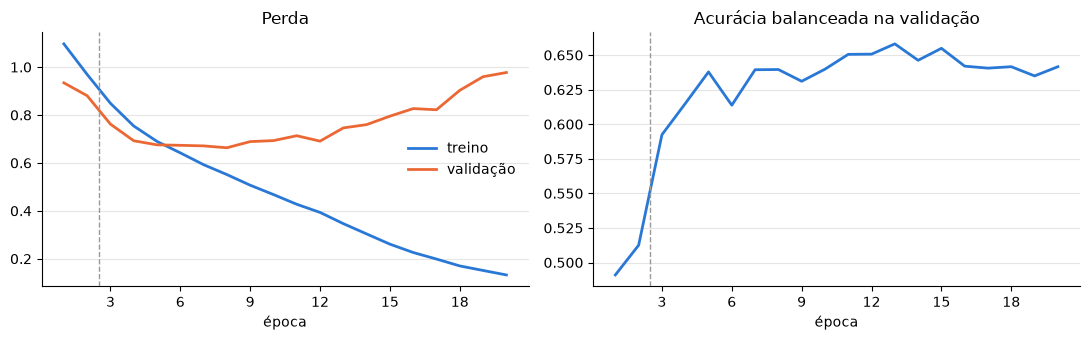

In [13]:
# Curvas de treino (a linha tracejada separa a fase 1, rede congelada, da fase 2)
h = pd.concat([pd.read_csv(OUT / "historico_fase1.csv"), pd.read_csv(OUT / "historico.csv")], ignore_index=True)
epoch = np.arange(1, len(h) + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
a1.plot(epoch, h["loss"], color="#2a78d6", lw=2, label="treino")
a1.plot(epoch, h["val_loss"], color="#eb6834", lw=2, label="validação")
a1.set(title="Perda", xlabel="época")
a1.legend(frameon=False)
a2.plot(epoch, h["val_bal_acc"], color="#2a78d6", lw=2)
a2.set(title="Acurácia balanceada na validação", xlabel="época")
for a in (a1, a2):
    a.axvline(HEAD_EPOCHS + 0.5, color="#999", ls="--", lw=1)
    a.spines[["top", "right"]].set_visible(False)
    a.grid(axis="y", color="#e5e5e5")
    a.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

# Teste

Avaliação no **teste do ISIC 2018** (1.511 imagens, 7 classes). Todas as escolhas, como a intensidade do ajuste de prior e o limiar da triagem, são feitas **só na validação** e depois aplicadas no teste, sem olhar o teste.

- **Comparação de variantes**: baseline da fase 1, ajuste fino e ajuste fino + TTA, para medir o ganho de cada etapa.
- **Relatório por classe e matriz de confusão**: onde o modelo acerta e com o que confunde cada lesão.
- **Triagem maligno × benigno**: limiar escolhido para **95% de sensibilidade** na validação. No uso clínico, deixar passar um câncer é muito pior do que mandar uma lesão benigna para biópsia.
- **Dermatologistas**: as mesmas imagens foram diagnosticadas por centenas de médicos num estudo publicado (Tschandl et al., *Nature Medicine* 2020), o que permite comparar o modelo com especialistas.
- **Uso do modelo salvo**: carrega o professor de `modelos/` e classifica uma imagem, como seria no consultório.


In [14]:
MALIGNANT_8 = [CLASS_IDX[c] for c in ["ak", "bcc", "mel", "scc"]]
MALIGNANT_7 = [HAM_IDX[c] for c in ["akiec", "bcc", "mel"]]


def adjust(p, tau):
    """Ajuste de logits: divide as probabilidades por prior**tau e renormaliza."""
    return softmax(np.log(p + 1e-12) - tau * LOG_PRIOR)


def to_ham(p):
    """8 classes -> 7 do HAM10000 (akiec = ak + scc), para comparar com o gabarito do teste."""
    return np.stack([p[:, CLASS_IDX["ak"]] + p[:, CLASS_IDX["scc"]] if c == "akiec" else p[:, CLASS_IDX[c]]
                     for c in HAM_CLASSES], axis=1)


def tune_tau(p_val):
    """Escolhe tau na validação (nunca no teste), maximizando a acurácia balanceada."""
    taus = np.arange(0, 2.01, 0.05)
    scores = [balanced_accuracy_score(y_val, adjust(p_val, t).argmax(1)) for t in taus]
    return float(taus[int(np.argmax(scores))])


def evaluate(p_val, p_test):
    tau = tune_tau(p_val)
    raw, adj = to_ham(p_test), to_ham(adjust(p_test, tau))
    return {
        "tau": tau,
        "val_bal_acc": balanced_accuracy_score(y_val, adjust(p_val, tau).argmax(1)),
        # acurácia comum: decisão sem ajuste (é o que maximiza acertos totais)
        "test_acc": accuracy_score(y_test, raw.argmax(1)),
        # acurácia balanceada: decisão ajustada (métrica oficial do ISIC)
        "test_bal_acc": balanced_accuracy_score(y_test, adj.argmax(1)),
        "test_acc_ajustada": accuracy_score(y_test, adj.argmax(1)),
        "test_auc_macro": roc_auc_score(y_test, raw, multi_class="ovr", labels=range(len(HAM_CLASSES))),
        "test_auc_maligno": roc_auc_score(np.isin(y_test, MALIGNANT_7), raw[:, MALIGNANT_7].sum(1)),
    }


# Quanto cada etapa acrescenta (mesmo critério de decisão para todas)
fase1 = dict(np.load(OUT / "probs_fase1.npz"))
FINAL = "Fase 2 + TTA (final)"
variants = {
    "Fase 1: rede congelada (baseline)": (fase1["val"], fase1["test"]),
    "Fase 2: ajuste fino": (probs["val_1view"], probs["test_1view"]),
    FINAL: (probs["val"], probs["test"]),
}
results = {k: evaluate(*v) for k, v in variants.items()}
pd.DataFrame(results).T.round(4)

,tau,val_bal_acc,test_acc,test_bal_acc,test_acc_ajustada,test_auc_macro,test_auc_maligno
Fase 1: rede congelada (baseline),0.95,0.5185,0.6711,0.4769,0.6598,0.8768,0.8672
Fase 2: ajuste fino,0.90,0.6612,0.8180,0.7244,0.8107,0.9572,0.9383
Fase 2 + TTA (final),0.90,0.6632,0.8220,0.7431,0.8193,0.9608,0.9426


              precision    recall  f1-score   support

       akiec      0.450     0.837     0.585        43
         bcc      0.827     0.667     0.738        93
         bkl      0.705     0.737     0.721       217
          df      0.556     0.682     0.612        44
         mel      0.688     0.503     0.581       171
          nv      0.912     0.919     0.915       908
        vasc      0.833     0.857     0.845        35

    accuracy                          0.819      1511
   macro avg      0.710     0.743     0.714      1511
weighted avg      0.827     0.819     0.819      1511



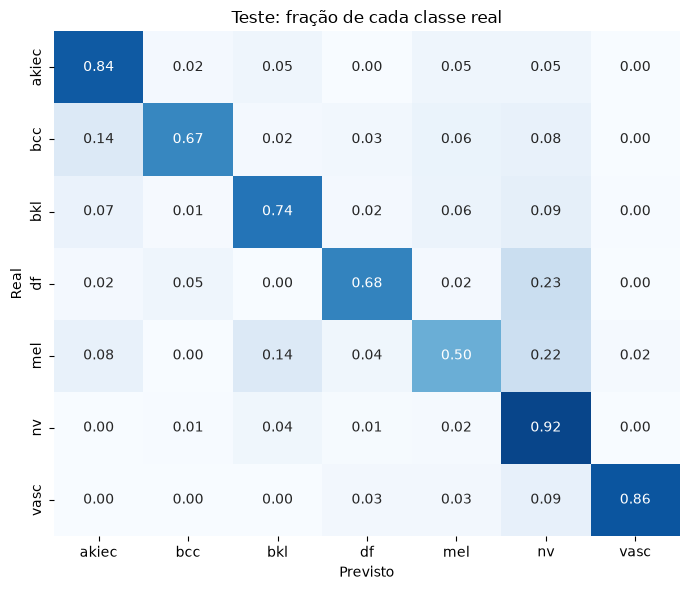

In [15]:
# Relatório por classe e matriz de confusão do modelo final (decisão ajustada)
tau = results[FINAL]["tau"]
pred = to_ham(adjust(probs["test"], tau)).argmax(1)
labels = list(range(len(HAM_CLASSES)))
print(classification_report(y_test, pred, labels=labels, target_names=HAM_CLASSES, digits=3, zero_division=0))

cm = confusion_matrix(y_test, pred, labels=labels, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
            xticklabels=HAM_CLASSES, yticklabels=HAM_CLASSES, ax=ax)
ax.set(xlabel="Previsto", ylabel="Real", title="Teste: fração de cada classe real")
plt.tight_layout()
plt.show()

In [16]:
# Triagem "maligno ou não" (mel, bcc, akiec). O limiar é escolhido na validação para
# sensibilidade de 95% (deixar passar um câncer é o erro mais grave) e só então aplicado no teste.
score_val = probs["val"][:, MALIGNANT_8].sum(1)
thr = np.quantile(score_val[np.isin(y_val, MALIGNANT_8)], 0.05)
score_test = to_ham(probs["test"])[:, MALIGNANT_7].sum(1)
mal_test = np.isin(y_test, MALIGNANT_7)
print(f"limiar (da validação): {thr:.3f}")
print(f"teste: sensibilidade {(score_test[mal_test] >= thr).mean():.3f}, "
      f"especificidade {(score_test[~mal_test] < thr).mean():.3f}, "
      f"AUC {roc_auc_score(mal_test, score_test):.3f}")

# Validação por origem: um modelo apoiado em atalhos de origem iria muito melhor numa que nas
# outras (as origens têm misturas de classes diferentes, então compare com cautela)
import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")  # o MSK só tem 3 classes
pred_val = adjust(probs["val"], tau).argmax(1)
by_source = {}
for src in ["HAM", "BCN", "MSK"]:
    m = (split["val"]["source"] == src).values
    if m.any():
        by_source[src] = {"imagens": int(m.sum()), "acurácia": accuracy_score(y_val[m], pred_val[m]),
                          "sensibilidade média": balanced_accuracy_score(y_val[m], pred_val[m])}
pd.DataFrame(by_source).T.round(3)

limiar (da validação): 0.045
teste: sensibilidade 0.958, especificidade 0.733, AUC 0.943


,imagens,acurácia,sensibilidade média
HAM,1510.0,0.849,0.719
BCN,1882.0,0.645,0.574
MSK,453.0,0.815,0.770


In [17]:
# Dermatologistas nas mesmas imagens do teste (Tschandl et al., Nature Medicine 2020): cada
# linha do CSV é um diagnóstico de um médico, sem e com o apoio da IA daquele estudo.
READERS_CSV = Path(os.environ.get(
    "READERS_CSV",
    Path.cwd().parent / "dataverse_files" / "ISIC2018_Task3_Test_NatureMedicine_AI_Interaction_Benefit.csv"))
if READERS_CSV.exists():
    nm = pd.read_csv(READERS_CSV, decimal=",")
    truth = split["test"].set_index("image_id")["dx_ham"].map(HAM_IDX)
    nm = nm[nm["image_id"].isin(truth.index)]
    y_nm = nm["image_id"].map(truth).values
    ours = pd.Series(pred, index=split["test"]["image_id"].values)

    def answers(prefix):
        return nm[[f"{prefix}_{c}" for c in HAM_CLASSES]].values.argmax(1)

    comp = {
        "Dermatologistas sem IA": answers("user_dx_without_interaction"),
        "Dermatologistas com a IA do estudo": answers("user_dx_with_interaction"),
        "IA do estudo": answers("prob_m_dx"),
        "Nosso professor": nm["image_id"].map(ours).values,
    }
    print(f"{len(nm)} diagnósticos em {nm['image_id'].nunique()} imagens do teste")
    display(pd.DataFrame({k: {"acurácia": accuracy_score(y_nm, v),
                              "acurácia balanceada": balanced_accuracy_score(y_nm, v)}
                          for k, v in comp.items()}).T.round(3))
else:
    print("CSV dos dermatologistas não encontrado:", READERS_CSV)

3762 diagnósticos em 1412 imagens do teste


,acurácia,acurácia balanceada
Dermatologistas sem IA,0.694,0.714
Dermatologistas com a IA do estudo,0.744,0.754
IA do estudo,0.782,0.777
Nosso professor,0.767,0.741


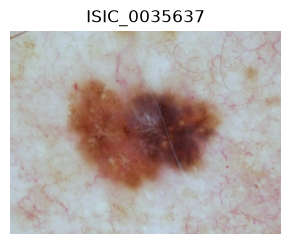

Diagnóstico real: Melanoma
Classes mais prováveis:
  Melanoma                          83.7%
  Nevo melanocítico                 11.1%
  Lesão benigna tipo queratose       1.9%
Triagem: probabilidade de malignidade 74.0% (limiar 4.5%) -> SUSPEITA, encaminhar para biópsia


In [18]:
# Usando o professor salvo: carrega o modelo de OUT e classifica uma imagem do teste
# (aqui, um melanoma), como seria no consultório
teacher = keras.models.load_model(OUT / "melhor.keras")
exemplo = split["test"][split["test"]["dx_ham"] == "mel"].sample(1, random_state=SEED)
p = predict_tta(teacher, exemplo, TTA_VIEWS)
p_adj = adjust(p, tau)[0]
score = p[0, MALIGNANT_8].sum()

fig, ax = plt.subplots(figsize=(3.5, 3.5))
ax.imshow(Image.open(exemplo["image_path"].iloc[0]))
ax.set_title(exemplo["file_id"].iloc[0])
ax.axis("off")
plt.show()

print("Diagnóstico real:", DX_NAMES[exemplo["dx_ham"].iloc[0]])
print("Classes mais prováveis:")
for i in np.argsort(p_adj)[::-1][:3]:
    print(f"  {DX_NAMES[CLASSES[i]]:<32} {p_adj[i]:6.1%}")
print(f"Triagem: probabilidade de malignidade {score:.1%} (limiar {thr:.1%}) ->",
      "SUSPEITA, encaminhar para biópsia" if score >= thr else "baixa suspeita")


# Fotos de celular

O professor foi treinado e testado em **dermatoscopia**, mas o uso que queremos (triagem pelo paciente ou pelo clínico geral) começa por uma **foto de celular**, sem lente. Avaliado nas duas bases públicas com fotos de celular confirmadas, **PAD-UFES-20** (Brasil, 2.298 fotos) e **HIBA** (Argentina, 345 fotos), o professor desaba: AUC de melanoma 0,59, sensibilidade 22%, os melanomas saem como `bkl` ou `nv`. A lente do dermatoscópio dá textura fina, cor calibrada e borda preta; a foto de celular tem foco ruim, ruído, compressão, sombra e balanço de branco errado, e a rede estava apoiada justamente nas pistas que somem.

**Experimento** (`scripts/treinar_simulando_celular.py`, 08/11/2026): ajuste fino do professor **sem nenhuma foto de celular** — só dermatoscopia (ISIC 2019, ISIC 2020, MILK10k) e fotos clínicas de câmera (MILK10k *close-up*, MED-NODE, MSKCC) — com uma **augmentation que simula celular**: recorte interno que tira a borda do dermatoscópio, lesão menor no quadro com fundo cor de pele, cor/contraste fortes, balanço de branco, sombra em gradiente, perda de resolução, desfoque, ruído de sensor e recompressão JPEG, cada efeito sorteado por imagem. Validação, melhor época, `tau` e limiar de triagem vêm só dessas bases; as fotos de celular são **teste puro** (2.643 fotos, 117 melanomas), medidas uma vez no fim, com TTA. Um controle com a mesma receita e sem a simulação mede o efeito isolado dela.

O modelo resultante está em `modelos/professor_simulando_celular/` (pesos, histórico, previsões e `README.md` com a receita). Ele **não substitui** o professor de dermatoscopia: é a versão para foto de celular. Abaixo, tudo é lido das previsões salvas, para não precisar das imagens (a pasta `data/` não vai para o repositório).

- **Antes × depois** no teste de celular, no total e por base.
- **Exemplos da augmentation** de simulação.
- **Curvas ROC** de melanoma e de maligno × benigno, e a troca sensibilidade × especificidade da triagem.
- **Matriz de confusão** do modelo novo nas fotos de celular.
- **Uso do modelo salvo**.


In [4]:
CEL = Path("modelos/professor_simulando_celular")
# Prior do treino desse ajuste (README), para o ajuste de logits; tau e limiar escolhidos na validação sem celular
PRIOR_CEL = np.array([910, 6384, 3145, 275, 4981, 6000, 1460, 280], dtype=float)
LOG_PRIOR_CEL = np.log(PRIOR_CEL / PRIOR_CEL.sum())
TAU_CEL, THR_CEL = 1.1, 0.287

comp = pd.read_csv(CEL / "comparacao.csv")
comp["modelo"] = comp["modelo"].str.replace("depois (B_dermatoscopia+fotos)", "depois (simulação de celular)", regex=False)
cols = ["modelo", "conjunto", "imagens", "melanomas", "acuracia", "acuracia_balanceada", "mel_sensibilidade",
        "mel_precisao", "mel_auc", "maligno_auc", "triagem_sensibilidade", "triagem_especificidade"]
comp[cols].set_index(["conjunto", "modelo"]).sort_index(level=0, sort_remaining=False).round(3)

imagens  \
conjunto                     modelo                                   
celular (PAD-UFES-20 + HIBA) antes (Felipe)                    2643   
                             depois (simulação de celular)     2643   
hiba                         antes (Felipe)                     345   
                             depois (simulação de celular)      345   
pad_ufes_20                  antes (Felipe)                    2298   
                             depois (simulação de celular)     2298   

                                                            melanomas  \
conjunto                     modelo                                     
celular (PAD-UFES-20 + HIBA) antes (Felipe)                       117   
                             depois (simulação de celular)        117   
hiba                         antes (Felipe)                        65   
                             depois (simulação de celular)         65   
pad_ufes_20                  antes (Felipe)                        52   
                             depois (simulação de celular)         52   

                                                            acuracia  \
conjunto                     modelo                                    
celular (PAD-UFES-20 + HIBA) antes (Felipe)                    0.315   
                             depois (simulação de celular)     0.389   
hiba                         antes (Felipe)                    0.304   
                             depois (simulação de celular)     0.406   
pad_ufes_20                  antes (Felipe)                    0.317   
                             depois (simulação de celular)     0.386   

                                                            acuracia_balanceada  \
conjunto                     modelo                                               
celular (PAD-UFES-20 + HIBA) antes (Felipe)                               0.303   
                             depois (simulação de celular)                0.478   
hiba                         antes (Felipe)                               0.279   
                             depois (simulação de celular)                0.428   
pad_ufes_20                  antes (Felipe)                               0.362   
                             depois (simulação de celular)                0.476   

                                                            mel_sensibilidade  \
conjunto                     modelo                                             
celular (PAD-UFES-20 + HIBA) antes (Felipe)                             0.222   
                             depois (simulação de celular)              0.504   
hiba                         antes (Felipe)                             0.200   
                             depois (simulação de celular)              0.369   
pad_ufes_20                  antes (Felipe)                             0.250   
                             depois (simulação de celular)              0.673   

                                                            mel_precisao  \
conjunto                     modelo                                        
celular (PAD-UFES-20 + HIBA) antes (Felipe)                        0.068   
                             depois (simulação de celular)         0.224   
hiba                         antes (Felipe)                        0.406   
                             depois (simulação de celular)         0.462   
pad_ufes_20                  antes (Felipe)                        0.037   
                             depois (simulação de celular)         0.166   

                                                            mel_auc  \
conjunto                     modelo                                   
celular (PAD-UFES-20 + HIBA) antes (Felipe)                   0.593   
                             depois (simulação de celular)    0.871   
hiba                         antes (Felipe)                   0.643   
                             depois (simulação de c

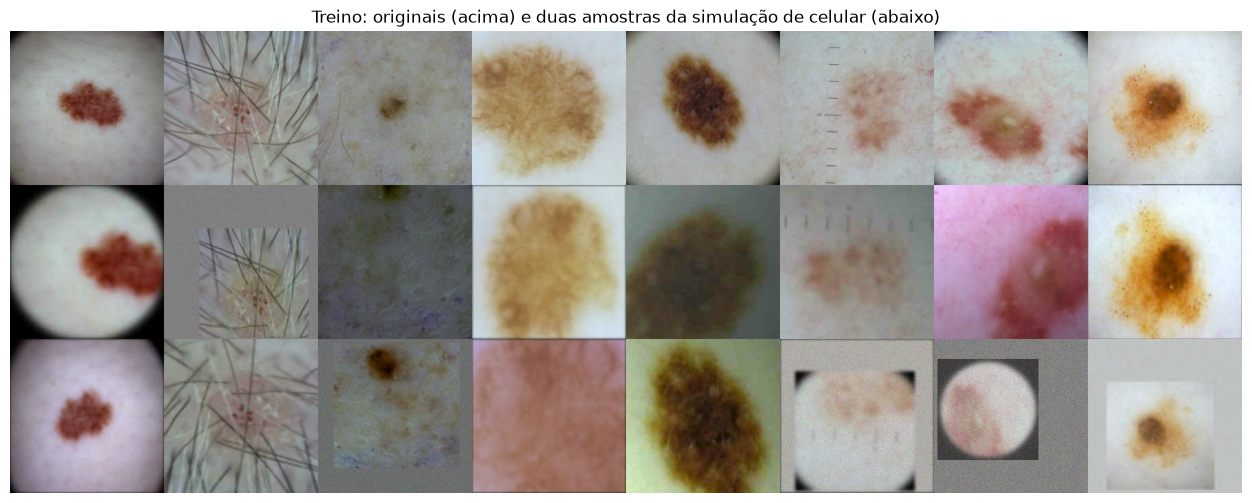

In [5]:
# Mosaico de conferência da augmentation: 1ª linha a imagem original (recorte central),
# 2ª e 3ª a mesma imagem após a augmentation do pipeline + simulação de celular
fig, ax = plt.subplots(figsize=(16, 6))
ax.imshow(Image.open(CEL / "augment_exemplos.jpg"))
ax.axis("off")
ax.set_title("Treino: originais (acima) e duas amostras da simulação de celular (abaixo)")
plt.show()

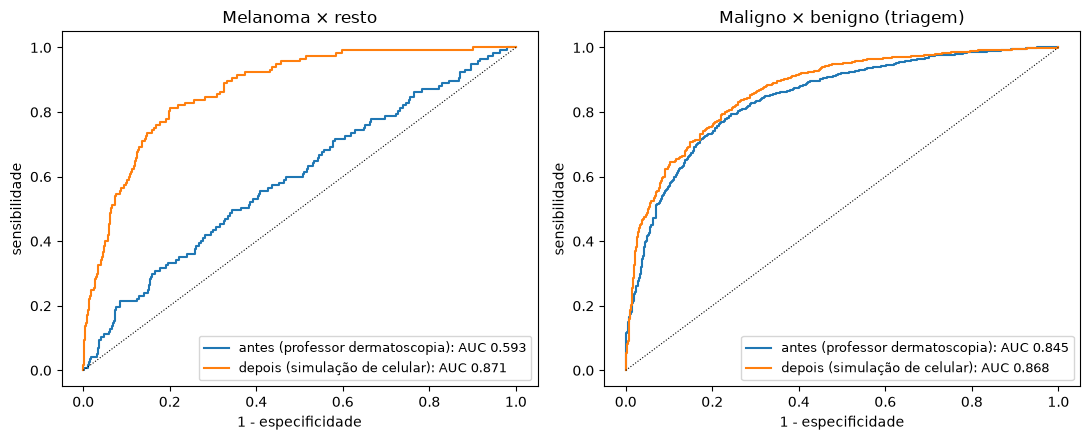

,sensibilidade,especificidade,melanomas perdidos,benignos encaminhados
limiar,,,,
0.287,0.966,0.412,15,341
0.400,0.941,0.540,23,267
0.500,0.907,0.617,33,222
0.600,0.869,0.690,43,180
0.700,0.802,0.764,57,137


In [6]:
from sklearn.metrics import roc_curve

prev = pd.read_csv(CEL / "previsoes_celular.csv")
y_cel = prev["dx"].map(CLASS_IDX).values
P_cel = {"antes (professor dermatoscopia)": prev[[f"antes_p_{c}" for c in CLASSES]].values,
         "depois (simulação de celular)": prev[[f"depois_p_{c}" for c in CLASSES]].values}
mel_cel = y_cel == CLASS_IDX["mel"]
mal_cel = np.isin(y_cel, MALIGNANT_8)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for nome, p in P_cel.items():
    for ax, (alvo, score, titulo) in zip(axes, [(mel_cel, p[:, CLASS_IDX["mel"]], "Melanoma × resto"),
                                               (mal_cel, p[:, MALIGNANT_8].sum(1), "Maligno × benigno (triagem)")]):
        fpr, tpr, _ = roc_curve(alvo, score)
        ax.plot(fpr, tpr, label=f"{nome}: AUC {roc_auc_score(alvo, score):.3f}")
        ax.set(xlabel="1 - especificidade", ylabel="sensibilidade", title=titulo)
for ax in axes:
    ax.plot([0, 1], [0, 1], "k:", lw=0.8)
    ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

# Triagem: o limiar escolhido na validação (dermatoscopia) fica agressivo no celular; a tabela
# mostra a troca sensibilidade × especificidade, que quem usa pode escolher
score_cel = P_cel["depois (simulação de celular)"][:, MALIGNANT_8].sum(1)
linhas = []
for thr_ in [THR_CEL, 0.4, 0.5, 0.6, 0.7]:
    enc = score_cel >= thr_
    linhas.append({"limiar": thr_, "sensibilidade": enc[mal_cel].mean(), "especificidade": (~enc[~mal_cel]).mean(),
                   "melanomas perdidos": int((mel_cel & ~enc).sum()), "benignos encaminhados": int((~mal_cel & enc).sum())})
pd.DataFrame(linhas).set_index("limiar").round(3)

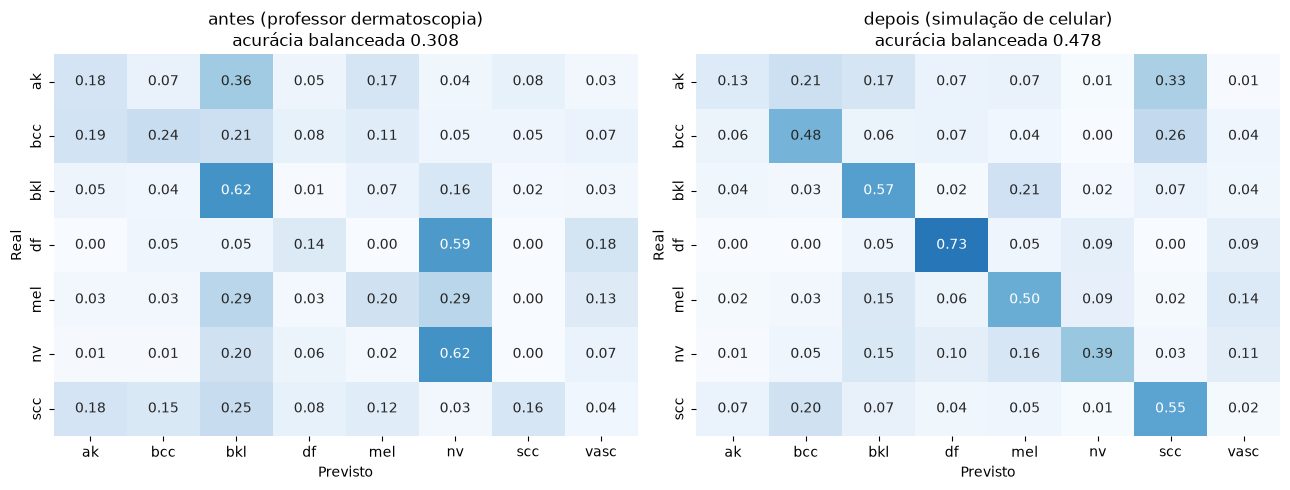

              precision    recall  f1-score   support

          ak      0.541     0.133     0.213       747
         bcc      0.663     0.477     0.555       959
         bkl      0.359     0.567     0.440       261
          df      0.088     0.727     0.158        22
         mel      0.224     0.504     0.311       117
          nv      0.806     0.391     0.526       297
         scc      0.200     0.550     0.294       240

   micro avg      0.406     0.389     0.397      2643
   macro avg      0.412     0.478     0.356      2643
weighted avg      0.548     0.389     0.406      2643



In [7]:
# Matriz de confusão nas fotos de celular (decisão ajustada pelo prior do treino, tau escolhido na validação).
# O teste não tem lesão vascular, por isso a linha vasc fica de fora.
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")  # vasc não existe no teste


def adjust_cel(p):
    return softmax(np.log(p + 1e-12) - TAU_CEL * LOG_PRIOR_CEL)

presentes = [i for i in range(len(CLASSES)) if (y_cel == i).any()]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (nome, p) in zip(axes, P_cel.items()):
    pred_cel = adjust_cel(p).argmax(1)
    cm_cel = confusion_matrix(y_cel, pred_cel, labels=list(range(len(CLASSES))), normalize="true")[presentes]
    sns.heatmap(cm_cel, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                xticklabels=CLASSES, yticklabels=[CLASSES[i] for i in presentes], ax=ax)
    ax.set(xlabel="Previsto", ylabel="Real",
           title=f"{nome}\nacurácia balanceada {balanced_accuracy_score(y_cel, pred_cel):.3f}")
plt.tight_layout()
plt.show()

pred_cel = adjust_cel(P_cel["depois (simulação de celular)"]).argmax(1)
print(classification_report(y_cel, pred_cel, labels=presentes, target_names=[CLASSES[i] for i in presentes],
                            digits=3, zero_division=0))

In [8]:
# Usando o modelo salvo. Mesma entrada do professor: imagem 224 px após Shades of Gray (0-255) e os
# 14 metadados; saída de 8 logits. Para decidir: softmax, ajuste com TAU_CEL e LOG_PRIOR_CEL,
# triagem pela soma das classes malignas contra THR_CEL (ver README da pasta).
celular = keras.models.load_model(CEL / "melhor.keras", compile=False)
print({k: tuple(v.shape) for k, v in zip(["image", "meta"], celular.inputs)}, "->", tuple(celular.output.shape))
print(f"parâmetros: {celular.count_params():,} | tau {TAU_CEL} | limiar de triagem {THR_CEL}")

{'image': (None, 224, 224, 3), 'meta': (None, 14)} -> (None, 8)
parâmetros: 5,931,288 | tau 1.1 | limiar de triagem 0.287


# Registro de iterações

## Iteração 1: EfficientNetV2-B0, 224 px, na CPU (07/11/2026)

**Configuração**: EfficientNetV2-B0 pré-treinada no ImageNet + metadados (idade, sexo, região do corpo); imagens com Shades of Gray, 224 px; fase 1 de 2 épocas só com a cabeça; fase 2 com ajuste fino da rede inteira com BatchNormalization congeladas, AdamW (lr de pico 3e-4, weight decay 0,02), aquecimento + cosseno, até 20 épocas com parada antecipada (paciência 5), batch 32; ajuste de prior com tau escolhido na validação; TTA de 8 visões.

**Treino**: ~7 h na CPU, com duas interrupções por falta de memória (retomado do backup). A melhor época foi a 11ª do ajuste fino; a parada antecipada encerrou o treino na 18ª.

| Variante | Acurácia balanceada (val, 8 classes) | Acurácia (teste) | Acurácia balanceada (teste, 7 classes) | AUC maligno × benigno (teste) |
|---|---|---|---|---|
| Fase 1: rede congelada (baseline) | 51,9% | 67,1% | 47,7% | 0,867 |
| Fase 2: ajuste fino | 66,1% | 81,8% | 72,4% | 0,938 |
| **Fase 2 + TTA (final)** | **66,3%** | **82,2%** | **74,3%** | **0,943** |

**Comparação com dermatologistas** (mesmas 1.412 imagens do teste, Tschandl et al., *Nature Medicine* 2020):

| | Acurácia | Acurácia balanceada |
|---|---|---|
| Dermatologistas sem IA | 69,4% | 71,4% |
| Dermatologistas com a IA do estudo | 74,4% | 75,4% |
| IA do estudo | 78,2% | 77,7% |
| **Nosso professor** | **76,7%** | **74,1%** |

**Triagem maligno × benigno**: com o limiar escolhido na validação para 95% de sensibilidade, o teste teve **95,8% de sensibilidade** e 73,3% de especificidade.

**Observações**
- O ajuste fino é o que mais pesa: +27 pontos de acurácia balanceada no teste sobre o baseline de embeddings congelados. O TTA soma cerca de +2 pontos.
- O professor já supera a média dos dermatologistas sem apoio da IA, mas ainda fica abaixo da IA do estudo.
- **Ponto fraco: melanoma**, com só 50% de sensibilidade quando a lesão é classificada sozinha. 22% dos melanomas saem como nevo e 14% como bkl. Na triagem com limiar de 95%, quase todos os casos malignos são sinalizados, mas a classe exata do melanoma ainda erra muito. O `df` também é confundido com nevo (23%).
- **Overfitting**: depois da época 8, a perda de validação sobe enquanto a de treino cai até 0,13. A acurácia balanceada estabiliza em ~64–66%. Mais regularização deve ajudar.
- **Por origem**: na validação, as imagens do BCN são as mais difíceis (64,5% de acurácia, contra 85% no HAM), e o teste vem todo do HAM. O BCN tem mais melanomas e lesões atípicas.
- A validação tem 8 classes, separando `ak` e `scc`, e o teste tem 7, com `akiec` juntando as duas. Por isso a acurácia balanceada do teste é maior.

**Próximos passos**
1. **Resolução e rede maiores na GPU do Kaggle** (EfficientNetV2-S, 384 px; `kaggle_professor.ipynb`): o maior ganho esperado, principalmente em melanoma, que depende de detalhes finos.
2. **Regularização contra o overfitting**: Mixup/CutMix, stochastic depth, EMA dos pesos.
3. **Ensemble** de professores com arquiteturas diferentes.
4. **Pseudo-rótulos** nas 6.726 imagens sem rótulo, que depois alimentam o aluno.

## Iteração 2: ajuste para foto de celular com simulação (08/11/2026)

**Motivação**: o professor da iteração 1, avaliado em bases que não viu, mantém AUC de melanoma 0,91 em dermatoscopia nova (ISIC 2019 teste, MILK10k) mas cai para 0,59 em fotos de celular (PAD-UFES-20 + HIBA).

**Configuração**: ajuste fino do `professor_effv2b0` (BatchNormalization congeladas, AdamW lr 1e-4 com aquecimento + cosseno, batch 32, até 8 épocas, paciência 3; melhor época a 7ª) em 23.435 imagens sem celular: ISIC 2019 treino, ISIC 2020, MILK10k dermatoscopia e *close-up*, MED-NODE, MSKCC e anônimas da ISIC, com nevos limitados a 6.000. Augmentation do pipeline + **simulação de celular** (recorte da borda, afastamento, cor forte, balanço de branco, sombra, resolução, desfoque, ruído, JPEG). Validação só nas mesmas bases (6.285 imagens), tau 1,1 e limiar 0,287 escolhidos nela. Três variantes: A só dermatoscopia + simulação; **B dermatoscopia + fotos de câmera + simulação**; C igual a B sem simulação (controle). ~2,5 h cada na CPU.

**Teste em fotos de celular** (PAD-UFES-20 + HIBA inteiras, 2.643 fotos, 117 melanomas, nenhuma vista no treino):

| Modelo | AUC melanoma | Sens. melanoma | Precisão melanoma | Acurácia balanceada | Triagem sens. / espec. |
|---|---|---|---|---|---|
| Professor da iteração 1 | 0,593 | 22% | 7% | 30% | 92% / 49% |
| A: só dermatoscopia + simulação | 0,735 | 26% | 13% | 40% | 91% / 61% |
| **B: + fotos de câmera + simulação (salvo em `modelos/`)** | **0,871** | **50%** | **22%** | **48%** | 97% / 41% |
| C: igual a B, sem simulação (controle) | 0,827 | 47% | 26% | 46% | 96% / 49% |

**Observações**
- A simulação de celular ajuda (B × C: +0,044 de AUC de melanoma, +3 pontos de sensibilidade), mas a maior parte do ganho vem de incluir fotos clínicas comuns no treino: só dermatoscopia + simulação (A) recupera menos da metade do caminho.
- No PAD-UFES-20 o B chega a AUC 0,915 e 67% de sensibilidade de melanoma; na HIBA, 0,817 e 37%. Não piora na dermatoscopia.
- O limiar de triagem transferido da validação em dermatoscopia fica agressivo no celular: 97% de sensibilidade mas 41% de especificidade (6 em 10 benignos encaminhados). Com limiar 0,5 fica em 91% / 62%. Precisa ser calibrado em foto de celular, com um conjunto separado do teste.
- A acurácia simples segue baixa (39%) porque o teste é dominado por `ak` e `bcc` em pele fotoenvelhecida, com muita confusão `ak` ↔ `bkl` ↔ `scc`. 58 dos 117 melanomas ainda recebem outra classe (`bkl` 17, `vasc` 16, `nv` 10, `df` 7); o `vasc`, classe rara inflada pelo ajuste de prior, é suspeito.
- Para comparação, um ajuste fino **com** fotos de celular no treino (não incluído no repositório) chegou a AUC de melanoma 0,96 num teste menor (401 fotos): dado real de celular ainda vale mais do que simulá-lo.

**Próximos passos**
1. Juntar as duas coisas: receita B (fotos + simulação) e depois ajuste fino com as fotos de celular disponíveis, guardando uma parte só para teste.
2. Calibrar tau e limiar de triagem em foto de celular.
3. Mais fotos de celular rotuladas (MRA-MIDAS, DDI; SCIN para lesões inflamatórias) e atacar a confusão `ak`/`bkl`/`scc`.
